# PA vs SPP — does the price adder ever exceed the settlement price?

**Question:** Is the RTM ORDC price **adder (PA)** always ≤ the RTM **settlement point price (SPP)**?
The adder is a *component* of the RTM SPP, so PA ≤ SPP should hold whenever the underlying
energy (system-lambda) component is ≥ 0.

**Inputs (all hour-ending, project standard):**
- Adders pre-2025: `3_analysis/price_adders_analysis/price_adders_numerical_analysis.csv`
  (`adder_effective = RTRSVPOR + RTRDP`, the online ORDC adder embedded in the price; `adder_sum` = all three)
- Adders post-2025 (RTC-B regime): `.../post_202512/post_202512_price_adders_hourly.csv` (`adder_sum` = 6 RTRDP* cols)
- RTM SPP pre-2025: `2_cleaned/rtm_price/rtm_price_aggregated_2021_2025.csv` (real 15-min RTM → HE hourly, corrected 2026-07-23)
- RTM SPP post-2025: `.../post_202512/rtm_price_mean_20251205_20260516.csv`

Merged on the raw HE timestamp (no shift — both series are hour-ending).

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path('../..').resolve()
PA_PRE   = ROOT/'01_data/3_analysis/price_adders_analysis/price_adders_numerical_analysis.csv'
RTM_PRE  = ROOT/'01_data/2_cleaned/rtm_price/rtm_price_aggregated_2021_2025.csv'
PA_POST  = ROOT/'01_data/3_analysis/price_adders_analysis/post_202512/post_202512_price_adders_hourly_20251205_20261024.csv'
RTM_POST = ROOT/'01_data/3_analysis/price_adders_analysis/post_202512/rtm_price_mean_20251205_20261024.csv'
OUT_DIR  = ROOT/'01_data/3_analysis/price_adders_analysis/pa_vs_spp'
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Pre-2025 (2021 – Dec 2025, legacy ORDC adders)

In [2]:
pa = pd.read_csv(PA_PRE, parse_dates=['date']).rename(columns={'date':'dt'})
pa['adder_effective'] = pa['RTRSVPOR'] + pa['RTRDP']
rtm = pd.read_csv(RTM_PRE, parse_dates=['date_time']).rename(columns={'date_time':'dt','avg_rtm_price':'spp'})[['dt','spp']]

pre = pa.merge(rtm, on='dt', how='inner')
pre = pre[pre['dt'] < '2025-12-05']
print(f"pre-2025 hours merged: {len(pre):,}  ({pre['dt'].min()} -> {pre['dt'].max()})")

pre-2025 hours merged: 43,146  (2021-01-01 01:00:00 -> 2025-12-03 23:00:00)


In [3]:
def report(df, adder_col, label):
    n = len(df)
    exc = df[(df[adder_col] > df['spp']) & (df[adder_col] > 0)]
    print(f"[{label}]  PA={adder_col}")
    print(f"  PA <= SPP holds: {n-len(exc):,}/{n:,}  ({100*(n-len(exc))/n:.3f}%)")
    print(f"  PA  > SPP (exceptions): {len(exc):,}  ({100*len(exc)/n:.3f}%)")
    if len(exc):
        print(f"    of exceptions, SPP < 0 : {(exc['spp']<0).sum()}  ({100*(exc['spp']<0).sum()/len(exc):.0f}%)")
        print(f"    exception SPP  : min={exc['spp'].min():.2f}  median={exc['spp'].median():.2f}  max={exc['spp'].max():.2f}")
        print(f"    exception PA   : min={exc[adder_col].min():.2f}  median={exc[adder_col].median():.2f}  max={exc[adder_col].max():.2f}")
    print()
    return exc

exc_pre_eff = report(pre, 'adder_effective', 'pre-2025')
exc_pre_sum = report(pre, 'adder_sum', 'pre-2025')

[pre-2025]  PA=adder_effective
  PA <= SPP holds: 43,107/43,146  (99.910%)
  PA  > SPP (exceptions): 39  (0.090%)
    of exceptions, SPP < 0 : 33  (85%)
    exception SPP  : min=-18.85  median=-1.84  max=3.50
    exception PA   : min=0.01  median=0.49  max=4.02

[pre-2025]  PA=adder_sum
  PA <= SPP holds: 43,082/43,146  (99.852%)
  PA  > SPP (exceptions): 64  (0.148%)
    of exceptions, SPP < 0 : 33  (52%)
    exception SPP  : min=-18.85  median=-0.03  max=8981.19
    exception PA   : min=0.01  median=1.43  max=9576.71



## 2. Post-2025 (Dec 2025+, RTC-B adders)

In [4]:
pap = pd.read_csv(PA_POST, parse_dates=['date']).rename(columns={'date':'dt'})
adder_cols = ['RTRDPA','RTRDPRU','RTRDPRD','RTRDPRRS','RTRDPECRS','RTRDPNS']
pap['adder_sum'] = pap[adder_cols].sum(axis=1)
rtmp = pd.read_csv(RTM_POST, parse_dates=['date_time']).rename(columns={'date_time':'dt','price':'spp'})[['dt','spp']]
post = pap.merge(rtmp, on='dt', how='inner')
print(f"post-2025 hours merged: {len(post):,}  ({post['dt'].min()} -> {post['dt'].max()})")
exc_post = report(post, 'adder_sum', 'post-2025')

post-2025 hours merged: 7,775  (2025-12-05 01:00:00 -> 2026-10-25 00:00:00)
[post-2025]  PA=adder_sum
  PA <= SPP holds: 7,482/7,775  (96.232%)
  PA  > SPP (exceptions): 293  (3.768%)
    of exceptions, SPP < 0 : 169  (58%)
    exception SPP  : min=-30.18  median=-0.38  max=1111.70
    exception PA   : min=0.07  median=1.74  max=1407.63



## 3. Cases with exceptions

In [5]:
exc_pre_eff = exc_pre_eff.assign(period='pre2025', adder=exc_pre_eff['adder_effective'])
exc_post2 = exc_post.assign(period='post2025', adder=exc_post['adder_sum'])
exceptions = pd.concat([
    exc_pre_eff[['dt','period','adder','spp']],
    exc_post2[['dt','period','adder','spp']],
], ignore_index=True).sort_values('dt')
exceptions.to_csv(OUT_DIR/'pa_gt_spp_exceptions_20261024.csv', index=False)
print(f"saved {len(exceptions)} PA>SPP exception hours -> {OUT_DIR/'pa_gt_spp_exceptions_20261024.csv'}")
exceptions

saved 332 PA>SPP exception hours -> /Users/zyliazhang/Git/ERCOT-Research/01_data/3_analysis/price_adders_analysis/pa_vs_spp/pa_gt_spp_exceptions_20261024.csv


,dt,period,adder,spp
0,2023-12-20 15:00:00,pre2025,0.0075,-0.021167
1,2024-03-03 03:00:00,pre2025,1.5125,0.555500
2,2024-03-03 04:00:00,pre2025,0.5525,-1.056167
3,2024-03-03 05:00:00,pre2025,0.8375,0.466167
4,2024-03-09 02:00:00,pre2025,0.3050,-0.045167
...,...,...,...,...
327,2026-10-16 18:00:00,post2025,6.2325,4.651583
328,2026-10-17 14:00:00,post2025,2.5850,1.153167
329,2026-10-17 15:00:00,post2025,4.5050,-0.242167
330,2026-10-17 16:00:00,post2025,12.7900,-0.322000


/var/folders/0q/ndh_pk0s37n95y6svtjfy7hw0000gp/T/ipykernel_42717/3492617603.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


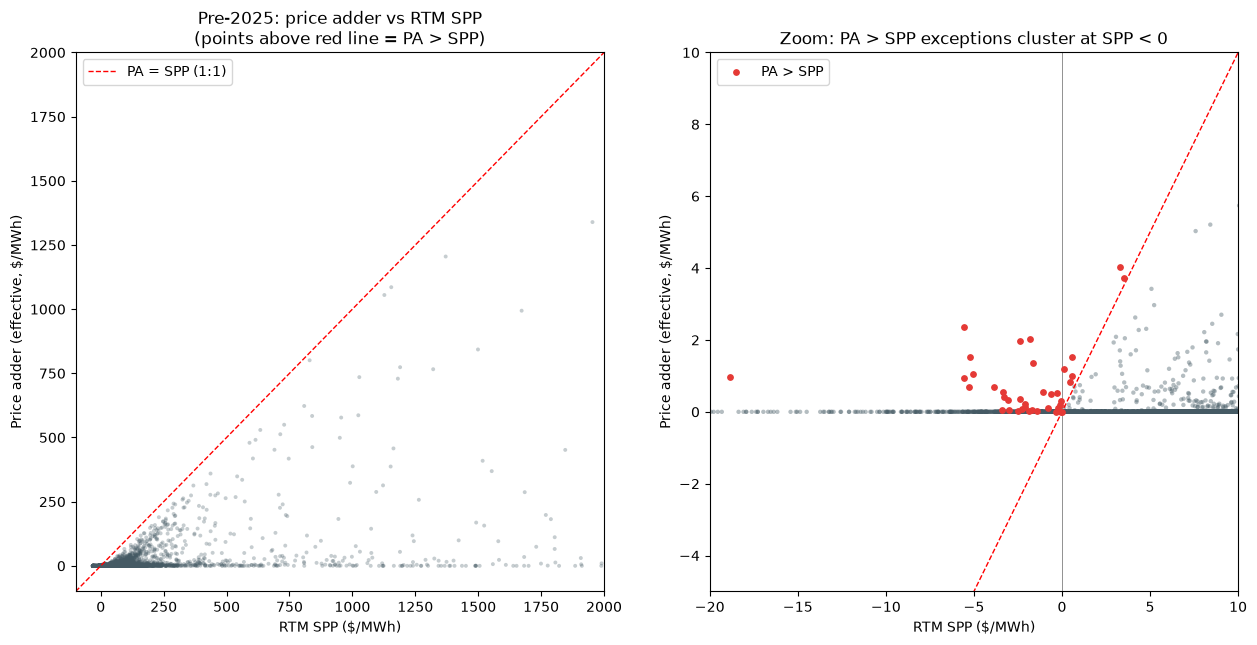

In [6]:
%matplotlib inline
# Scatter: PA (effective, pre-2025) vs SPP with the 1:1 line. Points above the line = PA>SPP.
fig, ax = plt.subplots(1, 2, figsize=(15,7))
ax[0].scatter(pre['spp'], pre['adder_effective'], s=8, alpha=0.3, color='#455A64', edgecolors='none')
lim = [-100, max(pre['spp'].max(), pre['adder_effective'].max())]
ax[0].plot(lim, lim, 'r--', lw=1, label='PA = SPP (1:1)')
ax[0].set_xlabel('RTM SPP ($/MWh)')
ax[0].set_ylabel('Price adder (effective, $/MWh)')
ax[0].set_title('Pre-2025: price adder vs RTM SPP\n(points above red line = PA > SPP)')
ax[0].legend()
ax[0].set_xlim(-100, 2000)
ax[0].set_ylim(-100, 2000)

# Zoom on the near-zero region where exceptions live
ax[1].scatter(pre['spp'], pre['adder_effective'], s=10, alpha=0.4, color='#455A64', edgecolors='none')
ax[1].scatter(exc_pre_eff['spp'], exc_pre_eff['adder'], s=15, color='#E53935', label='PA > SPP', zorder=3)
ax[1].plot([-40,40],[-40,40],'r--',lw=1)
ax[1].axvline(0, color='gray', lw=0.6)
ax[1].set_xlabel('RTM SPP ($/MWh)')
ax[1].set_ylabel('Price adder (effective, $/MWh)')
ax[1].set_title('Zoom: PA > SPP exceptions cluster at SPP < 0')
ax[1].legend()
ax[1].set_xlim(-20, 10)
ax[1].set_ylim(-5, 10)
fig.savefig(OUT_DIR/'pa_vs_spp_exceptions_pre2025.png', dpi=150, bbox_inches='tight')
fig.show()

/var/folders/0q/ndh_pk0s37n95y6svtjfy7hw0000gp/T/ipykernel_42717/374485752.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


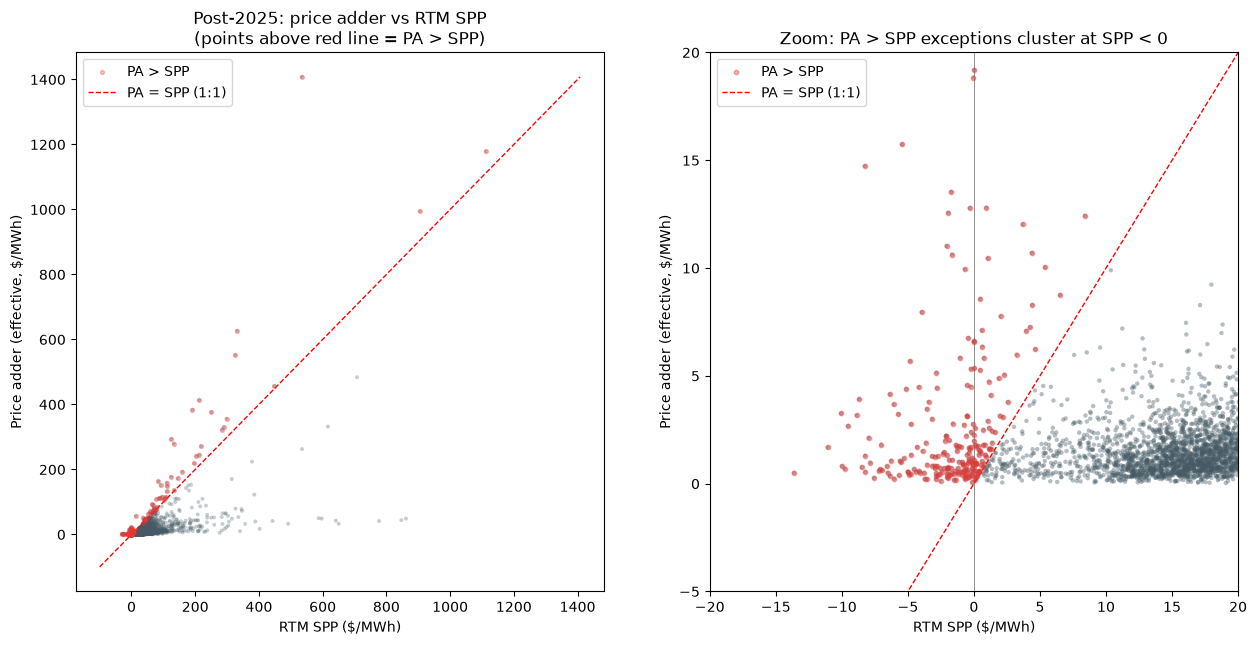

In [7]:
%matplotlib inline
# Scatter: PA (effective, post-2025) vs SPP with the 1:1 line. Points above the line = PA>SPP.
fig, ax = plt.subplots(1, 2, figsize=(15,7))
ax[0].scatter(post['spp'], post['adder_sum'], s=8, alpha=0.3, color='#455A64', edgecolors='none')
ax[0].scatter(exc_post['spp'], exc_post['adder_sum'], s=8, alpha=0.3, color='#E53935', label='PA > SPP', zorder=3)
lim = [-100, max(post['spp'].max(), post['adder_sum'].max())]
ax[0].plot(lim, lim, 'r--', lw=1, label='PA = SPP (1:1)')
ax[0].set_xlabel('RTM SPP ($/MWh)')
ax[0].set_ylabel('Price adder (effective, $/MWh)')
ax[0].set_title('Post-2025: price adder vs RTM SPP\n(points above red line = PA > SPP)')
ax[0].legend()

# Zoom on the near-zero region where exceptions live
ax[1].scatter(post['spp'], post['adder_sum'], s=10, alpha=0.4, color='#455A64', edgecolors='none')
ax[1].scatter(exc_post['spp'], exc_post['adder_sum'], s=10, alpha=0.4, color='#E53935', label='PA > SPP', zorder=3)
ax[1].plot(lim, lim, 'r--', lw=1, label='PA = SPP (1:1)')
ax[1].axvline(0, color='gray', lw=0.6)
ax[1].set_xlabel('RTM SPP ($/MWh)')
ax[1].set_ylabel('Price adder (effective, $/MWh)')
ax[1].set_title('Zoom: PA > SPP exceptions cluster at SPP < 0')
ax[1].legend()
ax[1].set_xlim(-20, 20)
ax[1].set_ylim(-5, 20)
fig.savefig(OUT_DIR/'pa_vs_spp_exceptions_post2025_20261024.png', dpi=150, bbox_inches='tight')
fig.show()

## Conclusion

PA ≤ SPP is **not** universal, but it holds in **~99.9%** of hours. Every exception sits at a
**near-zero or negative SPP** (≈85% have SPP < 0): when the energy/system-lambda component is
negative (oversupply, high renewables), the small standalone reserve adder exceeds the depressed
total settlement price. This is economically valid — the adder *is* embedded in the SPP, so it can
only exceed the total when the non-adder component is negative — **not** a data artifact.

Context: the earlier apparent PA>SPP problem was inflated by two now-fixed bugs — comparing against
**Day-Ahead** prices (178–220 exceptions) and a **1-hour** HE/HS misalignment. With corrected RTM
prices + HE alignment, exceptions drop to 39 (pre-2025) and are fully explained by negative-price hours.